In [1]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict, Counter
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

stemmer = PorterStemmer()

print("Stopwords downloaded successfully!")

Stopwords downloaded successfully!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aaditya\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [3]:
# Create a collection of documents

documents = {
    "D1": "Python is a programming language used for software development.",
    "D2": "Python is widely used in machine learning and artificial intelligence.",
    "D3": "Machine learning uses algorithms to analyze data.",
    "D4": "Information retrieval helps users search and retrieve documents.",
    "D5": "Search engines use indexing to find relevant information."
}

print("DOCUMENT COLLECTION")
print("-------------------")

for doc_id, content in documents.items():
    print(doc_id, ":", content)

DOCUMENT COLLECTION
-------------------
D1 : Python is a programming language used for software development.
D2 : Python is widely used in machine learning and artificial intelligence.
D3 : Machine learning uses algorithms to analyze data.
D4 : Information retrieval helps users search and retrieve documents.
D5 : Search engines use indexing to find relevant information.


In [4]:
def preprocess(text):

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenize
    words = text.split()

    # Remove stopwords and apply stemming
    processed_words = []

    for word in words:

        if word not in stop_words:

            stemmed_word = stemmer.stem(word)

            processed_words.append(stemmed_word)

    return processed_words


# Preprocess all documents

processed_documents = {}

for doc_id, content in documents.items():

    processed_documents[doc_id] = preprocess(content)


print("PREPROCESSED DOCUMENTS")
print("----------------------")

for doc_id, words in processed_documents.items():

    print(doc_id, ":", words)

PREPROCESSED DOCUMENTS
----------------------
D1 : ['python', 'program', 'languag', 'use', 'softwar', 'develop']
D2 : ['python', 'wide', 'use', 'machin', 'learn', 'artifici', 'intellig']
D3 : ['machin', 'learn', 'use', 'algorithm', 'analyz', 'data']
D4 : ['inform', 'retriev', 'help', 'user', 'search', 'retriev', 'document']
D5 : ['search', 'engin', 'use', 'index', 'find', 'relev', 'inform']


In [5]:
# Create an empty inverted index

inverted_index = defaultdict(list)

# Build the index

for doc_id, words in processed_documents.items():

    for word in set(words):

        inverted_index[word].append(doc_id)


print("INVERTED INDEX")
print("--------------")

for word, doc_ids in sorted(inverted_index.items()):

    print(word, ":", doc_ids)

INVERTED INDEX
--------------
algorithm : ['D3']
analyz : ['D3']
artifici : ['D2']
data : ['D3']
develop : ['D1']
document : ['D4']
engin : ['D5']
find : ['D5']
help : ['D4']
index : ['D5']
inform : ['D4', 'D5']
intellig : ['D2']
languag : ['D1']
learn : ['D2', 'D3']
machin : ['D2', 'D3']
program : ['D1']
python : ['D1', 'D2']
relev : ['D5']
retriev : ['D4']
search : ['D4', 'D5']
softwar : ['D1']
use : ['D1', 'D2', 'D3', 'D5']
user : ['D4']
wide : ['D2']


In [6]:
def search_documents(query):

    # Preprocess query
    query_words = preprocess(query)

    retrieved_documents = set()

    # Search each query word in the inverted index
    for word in query_words:

        if word in inverted_index:

            retrieved_documents.update(inverted_index[word])

    return sorted(retrieved_documents)


# Example search query

query = "Python machine learning"

results = search_documents(query)

print("SEARCH QUERY:", query)

print("\nRETRIEVED DOCUMENTS:")
print(results)

SEARCH QUERY: Python machine learning

RETRIEVED DOCUMENTS:
['D1', 'D2', 'D3']


In [7]:
print("RETRIEVED DOCUMENT DETAILS")
print("--------------------------")

if results:

    for doc_id in results:

        print("\nDocument:", doc_id)

        print("Content:", documents[doc_id])

else:

    print("No matching documents found.")

RETRIEVED DOCUMENT DETAILS
--------------------------

Document: D1
Content: Python is a programming language used for software development.

Document: D2
Content: Python is widely used in machine learning and artificial intelligence.

Document: D3
Content: Machine learning uses algorithms to analyze data.


In [8]:
def rank_documents(query):

    query_words = preprocess(query)

    scores = Counter()

    for word in query_words:

        for doc_id in inverted_index.get(word, []):

            scores[doc_id] += 1

    ranked_results = sorted(
        scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return ranked_results


ranked_results = rank_documents(query)

print("RANKED SEARCH RESULTS")
print("---------------------")

for doc_id, score in ranked_results:

    print(
        "Document:", doc_id,
        "| Relevance Score:", score
    )

RANKED SEARCH RESULTS
---------------------
Document: D2 | Relevance Score: 3
Document: D3 | Relevance Score: 2
Document: D1 | Relevance Score: 1


In [9]:
# Actual relevant documents for the example query
relevant_documents = {"D1", "D2", "D3"}

# Retrieved documents
retrieved_set = set(results)

# Calculate true positive documents
relevant_retrieved = (
    retrieved_set.intersection(relevant_documents)
)

# Calculate precision
if len(retrieved_set) > 0:

    precision = (
        len(relevant_retrieved) / len(retrieved_set)
    )

else:

    precision = 0


# Calculate recall
if len(relevant_documents) > 0:

    recall = (
        len(relevant_retrieved) / len(relevant_documents)
    )

else:

    recall = 0


# Calculate F1-score
if precision + recall > 0:

    f1_score = (
        2 * precision * recall / (precision + recall)
    )

else:

    f1_score = 0


print("INFORMATION RETRIEVAL EVALUATION")
print("--------------------------------")

print("Relevant Documents:", relevant_documents)

print("Retrieved Documents:", retrieved_set)

print("Relevant Retrieved:", relevant_retrieved)

print("Precision:", round(precision, 2))

print("Recall:", round(recall, 2))

print("F1 Score:", round(f1_score, 2))

INFORMATION RETRIEVAL EVALUATION
--------------------------------
Relevant Documents: {'D1', 'D2', 'D3'}
Retrieved Documents: {'D1', 'D2', 'D3'}
Relevant Retrieved: {'D1', 'D2', 'D3'}
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [10]:
## Metric	Formula	Meaning
##Precision	Relevant retrieved / Total retrieved	How many retrieved documents are relevant?
#Recall	Relevant retrieved / Total relevant	How many relevant documents were found?
#F1-score	2 × P × R / (P + R)	Balance between precision and recall

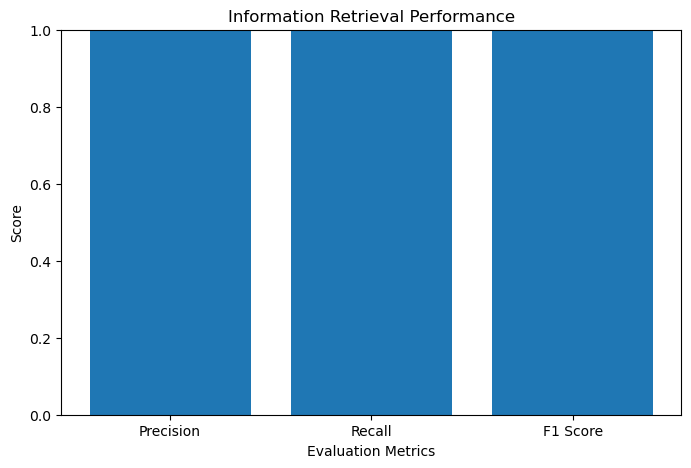

In [11]:
metrics = {
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_score
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)

plt.xlabel("Evaluation Metrics")

plt.ylabel("Score")

plt.title("Information Retrieval Performance")

plt.show()

In [12]:
index_data = []

for word, doc_ids in sorted(inverted_index.items()):

    index_data.append({
        "Term": word,
        "Document IDs": ", ".join(doc_ids),
        "Frequency": len(doc_ids)
    })


index_df = pd.DataFrame(index_data)

print("INVERTED INDEX TABLE")

display(index_df)

INVERTED INDEX TABLE


,Term,Document IDs,Frequency
0,algorithm,D3,1
1,analyz,D3,1
2,artifici,D2,1
3,data,D3,1
4,develop,D1,1
5,document,D4,1
6,engin,D5,1
7,find,D5,1
8,help,D4,1
9,index,D5,1


In [13]:
print("""
CONCLUSION:

The inverted file technique was successfully implemented
using Python.

The documents were preprocessed using stop word removal
and stemming.

An inverted index was created to map each term to the
documents containing that term.

The search query was processed and matching documents
were retrieved using the inverted index.

Retrieved documents were ranked based on matching terms.

Precision, Recall and F1-score were calculated to evaluate
the retrieval performance.

Thus, indexing and searching using inverted files were
successfully demonstrated.
""")


CONCLUSION:

The inverted file technique was successfully implemented
using Python.

The documents were preprocessed using stop word removal
and stemming.

An inverted index was created to map each term to the
documents containing that term.

The search query was processed and matching documents
were retrieved using the inverted index.

Retrieved documents were ranked based on matching terms.

Precision, Recall and F1-score were calculated to evaluate
the retrieval performance.

Thus, indexing and searching using inverted files were
successfully demonstrated.



In [ ]:
## Algorithm
1. Start the program.
2. Import the required libraries.
3. Create a collection of text documents.
4. Convert documents to lowercase.
5. Remove punctuation and stop words.
6. Apply stemming.
7. Create an inverted index.
8. Accept a search query.
9. Search the inverted index for query terms.
10. Retrieve matching documents.
11. Rank documents based on matching terms.
12. Calculate Precision, Recall and F1-score.
13. Display the results and graph.
14. Stop.
5. Viva questions and answers
Q1. What is an inverted file?

An inverted file is an indexing structure that maps each term to the documents containing that term.

Q2. What is indexing?

Indexing is the process of organizing document terms to enable faster searching.

Q3. Why do we use an inverted index?

To retrieve relevant documents quickly without scanning every document for every query.

Q4. What is a posting list?

A posting list contains the document IDs in which a particular term appears.

Q5. What is a dictionary in an inverted index?

It contains all unique terms along with their corresponding posting lists.

Q6. What is document retrieval?

Finding documents relevant to a user's search query.

Q7. What is tokenization?

Breaking text into individual words or tokens.

Q8. What is stemming?

Reducing words to their root-like form.

Q9. What are stop words?

Common words such as is, the, are, and a.

Q10. What is precision?

Precision measures the proportion of retrieved documents that are relevant.

Q11. What is recall?

Recall measures the proportion of all relevant documents that were retrieved.

Q12. What is F1-score?

It is the harmonic mean of precision and recall.

Q13. What is a search query?

A search query is the text entered by a user to find relevant documents.

Q14. What is ranking?

Ranking arranges retrieved documents according to their relevance scores.

Q15. Where are inverted indexes used?

Search engines, digital libraries, document databases, and information retrieval systems.

Q16. What is the difference between a forward index and an inverted index?

A forward index maps documents to their terms, whereas an inverted index maps terms to their documents.

Q17. What is Web Mining?

Web Mining extracts useful information and patterns from web content, links, and usage data.

Q18. What is the advantage of a posting list?

It allows quick identification of documents containing a particular word.

Q19. What happens if a search term is not present in the index?

The system returns no matching documents for that term.

Q20. Which Python data structure is used to create the inverted index here?

defaultdict from the collections module.

6. Quick revision for viva
Term	Remember this
Inverted index	Word → Document IDs
Indexing	Organizing terms
Posting list	List of document IDs
Retrieval	Finding relevant documents
Precision	Accuracy of retrieved results
Recall	Coverage of relevant results
F1-score	Balance of precision and recall
Ranking	Ordering by relevance

Important practical note: This implementation uses OR-based retrieval: a document is returned if it contains at least one query term. The relevance labels are manually assigned for the example query, so the evaluation scores measure this sample setup, not a general search engine's performance.